# Initial Exploration: NASA Exoplanet Archive, Planetary Systems (PS) Table

**Source:** NASA Exoplanet Archive, *Planetary Systems* table, downloaded 2026-10-11 20:14:11
(`data/PS_2026.10.11_20.14.11.csv`).

This notebook loads the data, checks what's there, and looks at a few key distributions and relationships.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# Reference categorical palette (light mode) + neutral for "Other"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})

# The file has 96 '#' header lines documenting each column
raw = pd.read_csv("data/PS_2026.10.11_20.14.11.csv", comment="#", low_memory=False)
raw.shape

(40336, 92)

## 1. Structure of the table

The PS table has **one row per (planet, published parameter set)**, so a planet measured by several papers appears several times.
`default_flag == 1` marks the archive's one chosen parameter set per planet. We use those rows for planet-level analysis.

In [2]:
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
print(f"Unique planets: {raw.pl_name.nunique():,}   Unique host stars: {raw.hostname.nunique():,}")
print("Parameter sets per planet:")
print(raw.groupby('pl_name').size().describe().round(2).to_string())

df = raw[raw.default_flag == 1].copy()
assert df.pl_name.is_unique
print(f"\nDefault-parameter rows (one per planet): {len(df):,}")
print(f"Controversial planets flagged: {int(df.pl_controv_flag.sum())}")

Rows: 40,336   Columns: 92
Unique planets: 6,445   Unique host stars: 4,842
Parameter sets per planet:
count    6445.00
mean        6.26
std         4.44
min         1.00
25%         2.00
50%         6.00
75%        10.00
max        34.00

Default-parameter rows (one per planet): 6,445
Controversial planets flagged: 58


## 2. Discovery method and year

In [3]:
m = df.discoverymethod.value_counts()
pd.DataFrame({"planets": m, "share_%": (100 * m / m.sum()).round(1)})

,planets,share_%
discoverymethod,,
Transit,4781,74.2
Radial Velocity,1203,18.7
Microlensing,292,4.5
Imaging,97,1.5
Transit Timing Variations,29,0.4
Eclipse Timing Variations,17,0.3
Orbital Brightness Modulation,9,0.1
Pulsar Timing,8,0.1
Astrometry,6,0.1


In [4]:
df.groupby("discoverymethod").disc_year.agg(["min", "median", "max"]).sort_values("min")

,min,median,max
discoverymethod,,,
Pulsar Timing,1992,2007.0,2024
Radial Velocity,1995,2016.0,2026
Transit,2002,2016.0,2026
Imaging,2004,2018.0,2026
Microlensing,2004,2022.0,2026
Pulsation Timing Variations,2007,2011.5,2016
Eclipse Timing Variations,2009,2012.0,2023
Orbital Brightness Modulation,2011,2014.0,2021
Transit Timing Variations,2011,2023.0,2026


## 3. Summary statistics for key variables

Planet properties are heavy-tailed (periods range from hours to millions of days), so we report medians and quartiles along with log-scale spread.
**Note:** `pl_bmasse` is a true mass *or* a minimum mass (M sin i) for radial-velocity planets; see `pl_bmassprov`.

In [5]:
key = {
    "pl_orbper": "Orbital period [days]",
    "pl_orbsmax": "Semi-major axis [au]",
    "pl_rade": "Planet radius [R_earth]",
    "pl_bmasse": "Planet mass [M_earth]",
    "pl_orbeccen": "Eccentricity",
    "pl_insol": "Insolation [S_earth]",
    "pl_eqt": "Equilibrium temp. [K]",
    "st_teff": "Stellar T_eff [K]",
    "st_mass": "Stellar mass [M_sun]",
    "st_met": "Stellar metallicity [dex]",
    "sy_dist": "Distance [pc]",
    "sy_pnum": "Planets in system",
}
s = df[list(key)].describe(percentiles=[.25, .5, .75]).T
s.insert(0, "missing_%", (100 * df[list(key)].isna().mean()).round(1))
s.index = [key[c] for c in s.index]
s[["missing_%", "count", "min", "25%", "50%", "75%", "max"]].round(2)

,missing_%,count,min,25%,50%,75%,max
Orbital period [days],5.8,6070.0,0.09,4.30,10.66,37.94,8040000.00
Semi-major axis [au],38.8,3946.0,0.00,0.05,0.12,0.84,19000.00
Planet radius [R_earth],25.3,4814.0,0.31,1.64,2.47,4.15,87.21
Planet mass [M_earth],50.7,3177.0,0.02,11.90,170.00,692.87,9534.85
Eccentricity,57.1,2763.0,0.00,0.00,0.08,0.21,0.95
Insolation [S_earth],85.3,945.0,0.00,9.90,62.90,387.40,9110.00
Equilibrium temp. [K],72.6,1767.0,50.00,570.00,900.00,1374.00,3921.00
Stellar T_eff [K],12.0,5669.0,415.00,4900.00,5544.00,5899.00,40000.00
Stellar mass [M_sun],13.7,5559.0,0.01,0.76,0.94,1.10,9.10
Stellar metallicity [dex],31.2,4432.0,-1.00,-0.08,0.02,0.12,0.79


**Missingness matters.** In the default parameter sets, about half of planets lack a mass, a quarter lack a radius, and most lack insolation / equilibrium temperature.
That's largely because of detection method: transits measure radius, radial velocity measures (minimum) mass. Some gaps can be filled from a planet's *non-default* rows in this same table (or from the archive's *PSCompPars* table), as shown below.

In [6]:
cov = (df.assign(has_mass=df.pl_bmasse.notna(), has_radius=df.pl_rade.notna())
         .groupby("discoverymethod")[["has_mass", "has_radius"]].mean().mul(100).round(1))
cov.insert(0, "n", df.discoverymethod.value_counts())
cov.sort_values("n", ascending=False).head(6)

,n,has_mass,has_radius
discoverymethod,,,
Transit,4781,31.9,99.3
Radial Velocity,1203,99.6,2.5
Microlensing,292,100.0,0.0
Imaging,97,95.9,30.9
Transit Timing Variations,29,100.0,10.3
Eclipse Timing Variations,17,100.0,0.0


In [7]:
# How many default-row gaps could be filled from another parameter set of the same planet?
for col in ["pl_bmasse", "pl_rade", "pl_orbeccen", "pl_insol", "pl_eqt"]:
    any_val = raw.groupby("pl_name")[col].apply(lambda x: x.notna().any())
    print(f"{col:12s} default rows: {100*df[col].notna().mean():5.1f}%  "
          f"| any row for the planet: {100*any_val.mean():5.1f}%")

pl_bmasse    default rows:  49.3%  | any row for the planet:  52.4%
pl_rade      default rows:  74.7%  | any row for the planet:  75.4%


pl_orbeccen  default rows:  42.9%  | any row for the planet:  83.4%
pl_insol     default rows:  14.7%  | any row for the planet:  70.3%


pl_eqt       default rows:  27.4%  | any row for the planet:  74.8%


## 4. Exploratory visualizations

### 4a. Discoveries per year, by method

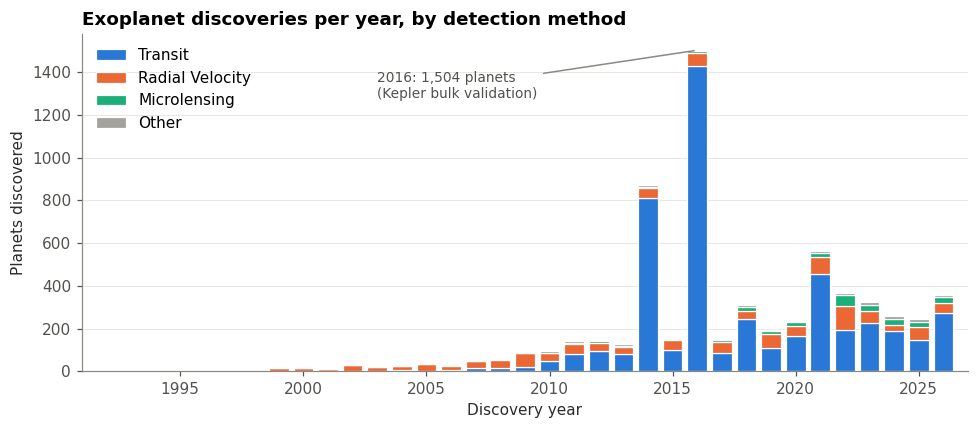

In [8]:
top = ["Transit", "Radial Velocity", "Microlensing"]
df["method"] = df.discoverymethod.where(df.discoverymethod.isin(top), "Other")
yr = df.groupby(["disc_year", "method"]).size().unstack(fill_value=0)[top + ["Other"]]

fig, ax = plt.subplots(figsize=(9, 4))
bottom = np.zeros(len(yr))
for col, c in zip(yr.columns, [BLUE, ORANGE, AQUA, GRAY]):
    ax.bar(yr.index, yr[col], bottom=bottom, color=c, width=0.8,
           edgecolor="white", linewidth=0.8, label=col)
    bottom += yr[col].values
ax.set_xlabel("Discovery year"); ax.set_ylabel("Planets discovered")
ax.set_title("Exoplanet discoveries per year, by detection method", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
ax.set_xlim(yr.index.min() - 1, yr.index.max() + 1)
ax.legend(loc="upper left")
peak = yr.sum(axis=1).idxmax()
ax.annotate(f"{peak}: {yr.sum(axis=1).max():,} planets\n(Kepler bulk validation)",
            xy=(peak, yr.sum(axis=1).max()), xytext=(peak - 13, yr.sum(axis=1).max() * 0.85),
            fontsize=9, color="#52514e", arrowprops=dict(arrowstyle="-", color="#8a8984"))
fig.tight_layout(); fig.savefig(FIG / "discoveries_by_year.png"); plt.show()

Transits dominate after 2014 (Kepler, then TESS). The 2016 spike is Kepler's statistical validation of ~1,500 candidates at once, a reminder that discovery year partly reflects **publication batches** and not just detection capability.

### 4b. Mass vs. orbital period: detection methods see different planets

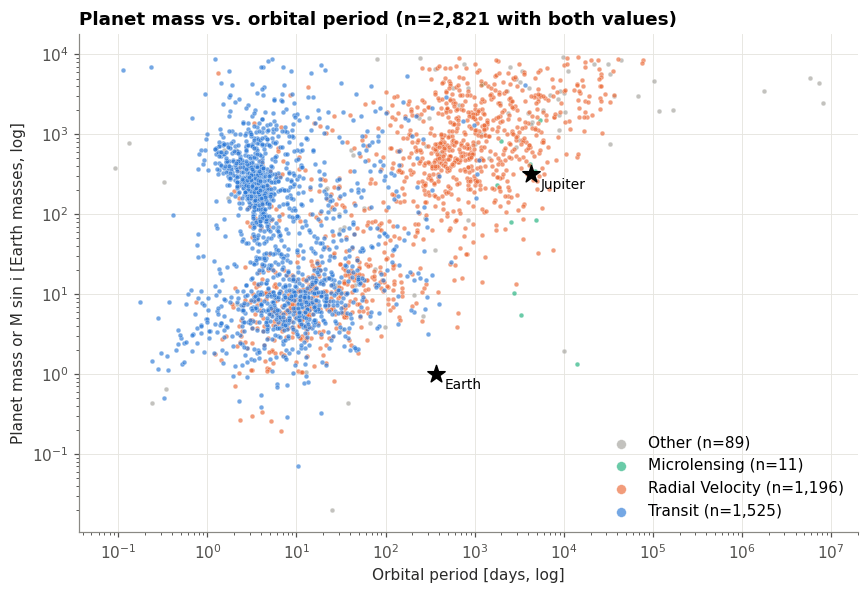

In [9]:
d = df.dropna(subset=["pl_orbper", "pl_bmasse"])
fig, ax = plt.subplots(figsize=(8, 5.5))
for name, c, z in [("Other", GRAY, 1), ("Microlensing", AQUA, 2),
                   ("Radial Velocity", ORANGE, 3), ("Transit", BLUE, 4)]:
    g = d[d.method == name]
    ax.scatter(g.pl_orbper, g.pl_bmasse, s=10, color=c, alpha=0.65,
               edgecolor="white", linewidth=0.3, label=f"{name} (n={len(g):,})", zorder=z)
for lab, p, mval in [("Earth", 365.25, 1), ("Jupiter", 4332.6, 317.8)]:
    ax.scatter(p, mval, marker="*", s=140, color="black", zorder=5)
    ax.annotate(lab, (p, mval), xytext=(6, -10), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Orbital period [days, log]"); ax.set_ylabel("Planet mass or M sin i [Earth masses, log]")
ax.set_title(f"Planet mass vs. orbital period (n={len(d):,} with both values)", loc="left", fontweight="bold")
ax.legend(loc="lower right", markerscale=2)
fig.tight_layout(); fig.savefig(FIG / "mass_vs_period.png"); plt.show()

In [10]:
# Correlation of log quantities (Spearman, robust to the heavy tails)
logv = np.log10(df[["pl_orbper", "pl_orbsmax", "pl_rade", "pl_bmasse", "pl_insol", "st_mass", "sy_dist"]].where(lambda x: x > 0))
logv.assign(pl_eqt=df.pl_eqt, st_met=df.st_met).corr(method="spearman").round(2)

,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_insol,st_mass,sy_dist,pl_eqt,st_met
pl_orbper,1.00,0.99,0.09,0.36,-0.64,0.16,-0.12,-0.67,-0.07
pl_orbsmax,0.99,1.00,-0.00,0.47,-0.46,0.12,-0.02,-0.46,-0.07
pl_rade,0.09,-0.00,1.00,0.83,0.43,0.37,-0.00,0.51,0.25
pl_bmasse,0.36,0.47,0.83,1.00,0.40,0.40,0.20,0.42,0.21
pl_insol,-0.64,-0.46,0.43,0.40,1.00,0.66,0.50,0.99,0.30
st_mass,0.16,0.12,0.37,0.40,0.66,1.00,0.15,0.61,0.30
sy_dist,-0.12,-0.02,-0.00,0.20,0.50,0.15,1.00,0.47,0.03
pl_eqt,-0.67,-0.46,0.51,0.42,0.99,0.61,0.47,1.00,0.26
st_met,-0.07,-0.07,0.25,0.21,0.30,0.30,0.03,0.26,1.00


The scatter shows strong **selection effects**: transits find mostly short-period planets (< ~100 days); radial velocity reaches longer periods but is biased to massive planets; microlensing finds cold planets at a few au. Few points sit near Earth's position, because Earth-analogs are at the edge of every method's sensitivity. Any question about "typical" planets needs to account for this.

### 4c. Planet radius distribution

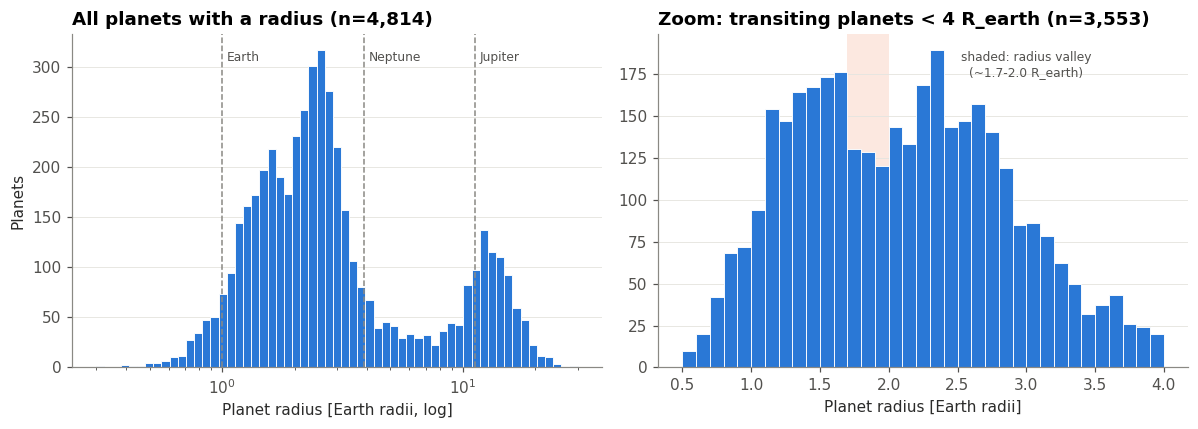

In [11]:
r = df.pl_rade.dropna()
r_tr = df.loc[(df.method == "Transit") & (df.pl_rade < 4), "pl_rade"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.hist(r, bins=np.logspace(np.log10(0.3), np.log10(30), 60), color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_xscale("log"); ax.set_xlabel("Planet radius [Earth radii, log]"); ax.set_ylabel("Planets")
ax.set_title(f"All planets with a radius (n={len(r):,})", loc="left", fontweight="bold")
for x, lab in [(1, "Earth"), (3.88, "Neptune"), (11.2, "Jupiter")]:
    ax.axvline(x, color="#8a8984", lw=1, ls="--")
    ax.text(x * 1.05, ax.get_ylim()[1] * 0.92, lab, fontsize=8, color="#52514e")
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.hist(r_tr, bins=np.linspace(0.5, 4, 36), color=BLUE, edgecolor="white", linewidth=0.6)
ax.axvspan(1.7, 2.0, color="#eb6834", alpha=0.15, lw=0, zorder=0)
ax.text(3.0, ax.get_ylim()[1] * 0.95, "shaded: radius valley\n(~1.7-2.0 R_earth)", ha="center", va="top", fontsize=8, color="#52514e")
ax.set_xlabel("Planet radius [Earth radii]")
ax.set_title(f"Zoom: transiting planets < 4 R_earth (n={len(r_tr):,})", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "radius_distribution.png"); plt.show()

The radius distribution is **bimodal**: a large population of super-Earths/sub-Neptunes (1-4 R⊕), a second peak of hot Jupiters (~10-15 R⊕), and comparatively few Saturn-sized planets in between. Zooming in on small transiting planets hints at the known **radius valley** (a dip near 1.7-2.0 R⊕), separating rocky super-Earths from gas-enveloped sub-Neptunes.

## 5. Takeaways for the project

- **6,445 confirmed planets** (40,336 parameter-set rows); use `default_flag == 1` for one row per planet, or merge across rows to fill gaps.
- Detection method drives which variables exist (radius vs. mass) and which planets appear, so method should be a control or a facet in any comparison.
- Core variables (period, distance, discovery year, method, system size) are nearly complete; mass, eccentricity, insolation and temperature are sparse.
- Distributions are heavy-tailed, so analyses and plots should use log scales.

### 4d. Planetary characteristics: mass, orbital distance, and outliers

Four complementary views of the exoplanet population focusing on planet size, mass, orbital architecture, and equilibrium temperature. Together they reveal the dominant patterns and the statistical outliers in the archive.

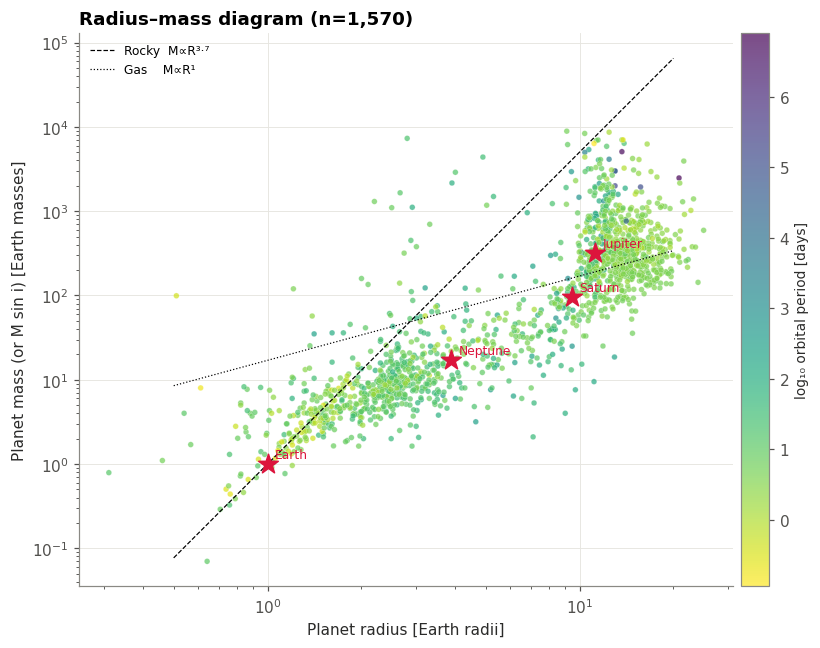

In [12]:
# ── 4d-1. Radius–mass diagram (the most fundamental planetary diagram) ──────
d_rm = df.dropna(subset=["pl_rade", "pl_bmasse"])

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(
    d_rm.pl_rade, d_rm.pl_bmasse,
    c=d_rm.pl_orbper.apply(np.log10),   # colour = log period
    cmap="viridis_r", s=14, alpha=0.7, edgecolor="white", linewidth=0.2
)
cb = fig.colorbar(sc, ax=ax, pad=0.01)
cb.set_label("log₁₀ orbital period [days]", fontsize=9)

# Solar-System reference points
for name, r, m in [("Earth", 1, 1), ("Neptune", 3.88, 17.1),
                   ("Saturn", 9.45, 95.2), ("Jupiter", 11.2, 317.8)]:
    ax.scatter(r, m, marker="*", s=180, color="crimson", zorder=6)
    ax.annotate(name, (r, m), xytext=(5, 4), textcoords="offset points",
                fontsize=8, color="crimson")

# Theoretical M-R lines
r_arr = np.logspace(np.log10(0.5), np.log10(20), 200)
ax.plot(r_arr, r_arr**3.7, "k--", lw=0.8, label="Rocky  M∝R³·⁷")   # rocky
ax.plot(r_arr, r_arr**1.0 * 17, "k:",  lw=0.8, label="Gas    M∝R¹")  # rough gas

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Planet radius [Earth radii]")
ax.set_ylabel("Planet mass (or M sin i) [Earth masses]")
ax.set_title(f"Radius–mass diagram (n={len(d_rm):,})", loc="left", fontweight="bold")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "radius_mass.png"); plt.show()


Short-period gas giants cluster in the upper-right; rocky planets hug the steep M∝R³·⁷ line at the lower-left. The colour gradient shows that short-period planets (dark) dominate the known population — a direct imprint of the transit selection effect. Planets far above the gas-giant sequence are likely highly inflated ("hot Jupiters" with bloated atmospheres).

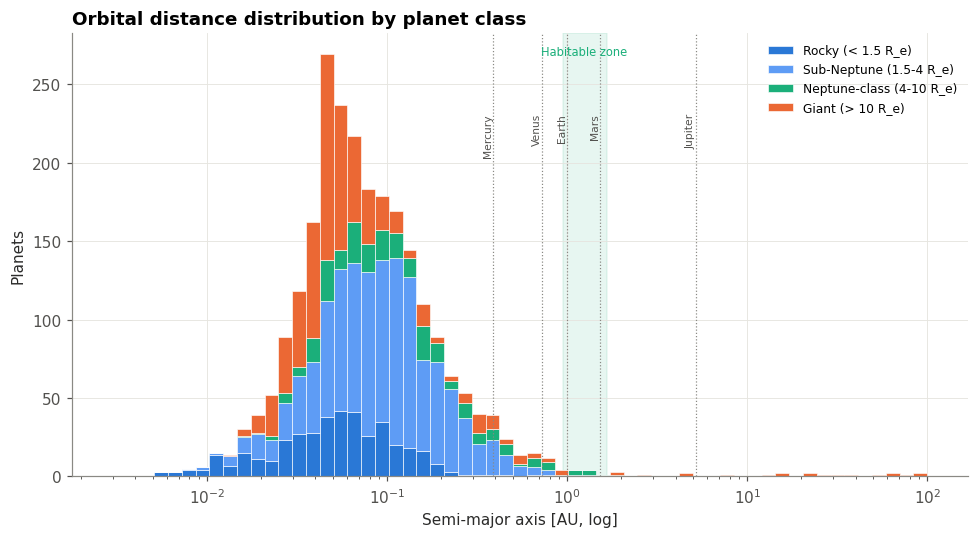

In [13]:
# ── 4d-2. Orbital semi-major axis distribution, by planet class ─────────────
def size_class(r):
    if pd.isna(r):           return np.nan
    if r < 1.5:              return "Rocky (< 1.5 R_e)"
    if r < 4:                return "Sub-Neptune (1.5-4 R_e)"
    if r < 10:               return "Neptune-class (4-10 R_e)"
    return                          "Giant (> 10 R_e)"

order   = ["Rocky (< 1.5 R_e)", "Sub-Neptune (1.5-4 R_e)",
           "Neptune-class (4-10 R_e)", "Giant (> 10 R_e)"]
palette = [BLUE, "#5e9cf5", AQUA, ORANGE]

df["size_class"] = df.pl_rade.apply(size_class)
d_sa = df.dropna(subset=["pl_orbsmax", "size_class"])

fig, ax = plt.subplots(figsize=(9, 5))
bins = np.logspace(np.log10(0.003), np.log10(100), 60)
bottom = np.zeros(len(bins) - 1)
for cls, c in zip(order, palette):
    vals = d_sa.loc[d_sa.size_class == cls, "pl_orbsmax"]
    counts, _ = np.histogram(vals, bins=bins)
    ax.bar(bins[:-1], counts, width=np.diff(bins), bottom=bottom,
           align="edge", color=c, edgecolor="white", linewidth=0.4, label=cls)
    bottom += counts

# Habitable-zone shading (rough solar-equivalent)
ax.axvspan(0.95, 1.67, color="#1baf7a", alpha=0.10, zorder=0)
ax.text(1.25, ax.get_ylim()[1] * 0.97, "Habitable zone", ha="center",
        va="top", fontsize=7.5, color="#1baf7a")

# Reference lines
for lab, a_val in [("Mercury", 0.387), ("Venus", 0.723), ("Earth", 1.0),
                   ("Mars", 1.52), ("Jupiter", 5.2)]:
    ax.axvline(a_val, color="#8a8984", lw=0.8, ls=":")
    ax.text(a_val, ax.get_ylim()[1] * 0.82, lab, rotation=90,
            va="top", ha="right", fontsize=7, color="#52514e")

ax.set_xscale("log")
ax.set_xlabel("Semi-major axis [AU, log]")
ax.set_ylabel("Planets")
ax.set_title("Orbital distance distribution by planet class", loc="left", fontweight="bold")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "semiaxis_by_class.png"); plt.show()


Giants and sub-Neptunes are overwhelmingly concentrated inside ~0.1 AU (the "hot" population), while rocky planets peak slightly further out but are still scarce beyond 1 AU — both because they are genuinely rare at wide orbits *and* because transits become geometrically less likely. The faint green band marks the approximate solar-equivalent habitable zone; it is notably underpopulated in the current census.

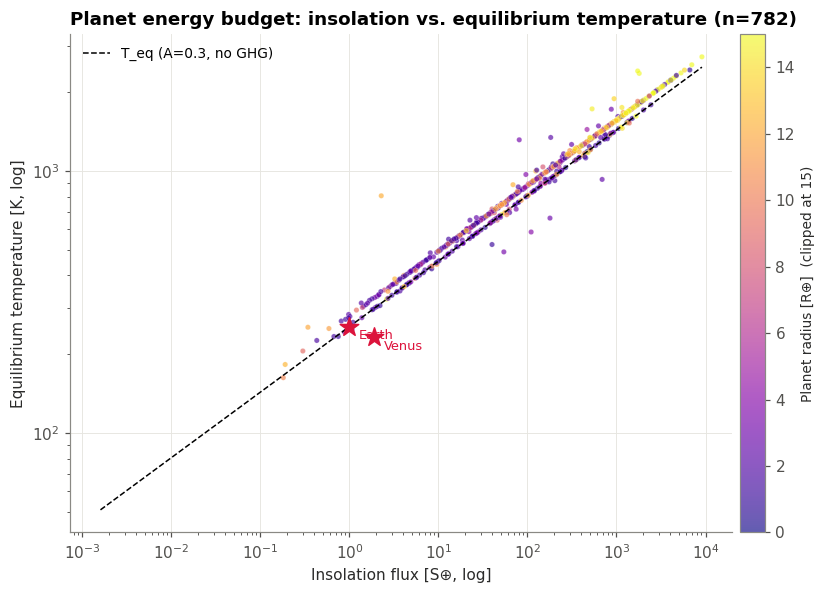

In [14]:
# ── 4d-3. Equilibrium temperature vs. insolation — the "energy budget" ──────
d_ei = df.dropna(subset=["pl_eqt", "pl_insol"])

fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(
    d_ei.pl_insol, d_ei.pl_eqt,
    c=d_ei.pl_rade, cmap="plasma", s=12, alpha=0.65,
    edgecolor="white", linewidth=0.2,
    vmin=0, vmax=15               # clip colour scale for clarity
)
cb = fig.colorbar(sc, ax=ax, pad=0.01)
cb.set_label("Planet radius [R⊕]  (clipped at 15)", fontsize=9)

# Theoretical T_eq ∝ S^0.25 line (Bond albedo 0.3)
s_arr = np.logspace(np.log10(d_ei.pl_insol.min()), np.log10(d_ei.pl_insol.max()), 200)
T_theory = 279 * s_arr**0.25 * (1 - 0.3)**0.25
ax.plot(s_arr, T_theory, "k--", lw=1, label="T_eq (A=0.3, no GHG)")

# Earth & Venus reference
for name, s_val, t_val in [("Earth", 1, 255), ("Venus", 1.91, 232)]:
    ax.scatter(s_val, t_val, marker="*", s=160, color="crimson", zorder=5)
    ax.annotate(name, (s_val, t_val), xytext=(6, -8),
                textcoords="offset points", fontsize=8.5, color="crimson")

# Annotate clear outliers (very hot, large planets)
outliers = d_ei[(d_ei.pl_eqt > 3000)].nlargest(4, "pl_eqt")
for _, row in outliers.iterrows():
    ax.annotate(row.pl_name, (row.pl_insol, row.pl_eqt),
                xytext=(5, 5), textcoords="offset points",
                fontsize=7, color="black",
                arrowprops=dict(arrowstyle="-", color="#aaa", lw=0.6))

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Insolation flux [S⊕, log]")
ax.set_ylabel("Equilibrium temperature [K, log]")
ax.set_title(f"Planet energy budget: insolation vs. equilibrium temperature (n={len(d_ei):,})",
             loc="left", fontweight="bold")
ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "temp_vs_insolation.png"); plt.show()


Most planets fall close to the theoretical T_eq ∝ S^0.25 line, confirming the relationship is physically driven. Colour encodes planet radius: large gas giants (bright yellow/orange) dominate the high-insolation, high-temperature region. The named outliers above ~3,000 K are **ultra-hot Jupiters** — tidally locked giants so close to their stars that their daysides exceed some stellar photospheres. Earth and Venus (crimson stars) sit far below the bulk of known exoplanets, marking a genuine detection gap for Earth-analogs.

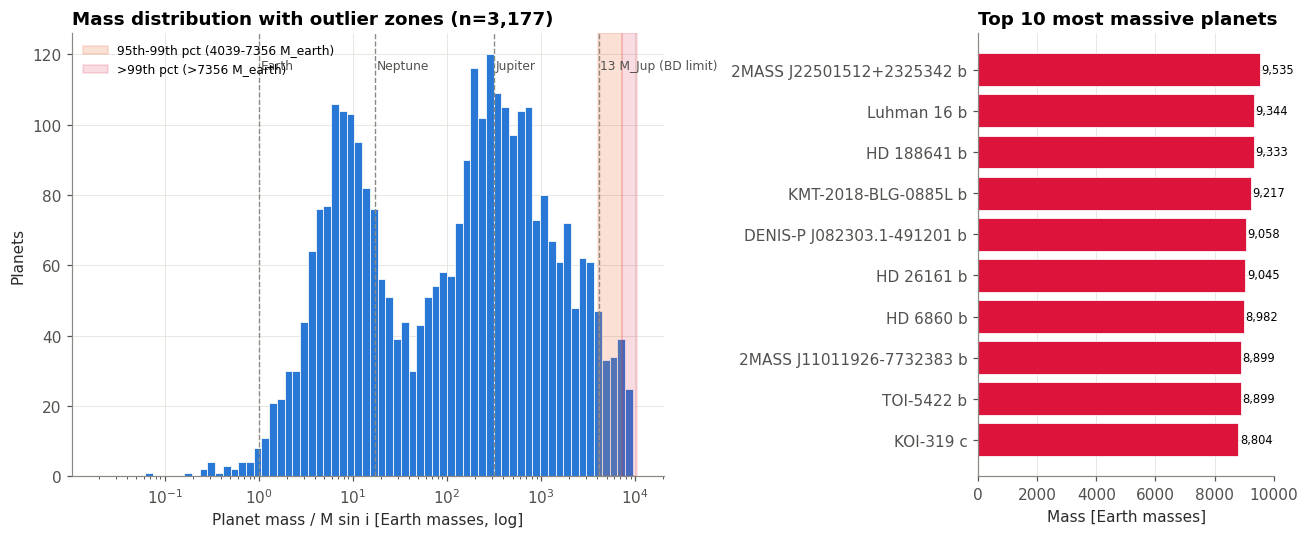

95th pct: 4039.0 M_earth = 12.7 M_Jup
99th pct: 7355.8 M_earth = 23.1 M_Jup
Most massive: 2MASS J22501512+2325342 b  (9535 M_earth = 30.0 M_Jup)


In [15]:
# ── 4d-4. Mass outlier strip-chart — how extreme are the most massive planets? ─
d_m = df.dropna(subset=["pl_bmasse"]).copy()

# Percentile thresholds
p95 = d_m.pl_bmasse.quantile(0.95)
p99 = d_m.pl_bmasse.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [2, 1]})

# LEFT: log-histogram with outlier zones shaded
ax = axes[0]
bins = np.logspace(np.log10(d_m.pl_bmasse.min()), np.log10(d_m.pl_bmasse.max()), 70)
ax.hist(d_m.pl_bmasse, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvspan(p95, p99, color=ORANGE, alpha=0.20,
           label=f"95th-99th pct ({p95:.0f}-{p99:.0f} M_earth)")
ax.axvspan(p99, d_m.pl_bmasse.max() * 1.1, color="crimson", alpha=0.15,
           label=f">99th pct (>{p99:.0f} M_earth)")
for lab, mval in [("Earth", 1), ("Neptune", 17.1), ("Jupiter", 317.8), ("13 M_Jup (BD limit)", 317.8*13)]:
    ax.axvline(mval, color="#8a8984", lw=0.9, ls="--")
    ax.text(mval * 1.04, ax.get_ylim()[1] * 0.92, lab, fontsize=8, color="#52514e")
ax.set_xscale("log")
ax.set_xlabel("Planet mass / M sin i [Earth masses, log]")
ax.set_ylabel("Planets")
ax.set_title(f"Mass distribution with outlier zones (n={len(d_m):,})", loc="left", fontweight="bold")
ax.legend(fontsize=8)

# RIGHT: top-10 most massive planets
ax2 = axes[1]
top10 = d_m.nlargest(10, "pl_bmasse")[["pl_name", "pl_bmasse"]].reset_index(drop=True)
colors_bar = ["crimson" if m > p99 else ORANGE for m in top10.pl_bmasse]
bars = ax2.barh(top10.pl_name[::-1], top10.pl_bmasse[::-1], color=colors_bar[::-1],
                edgecolor="white", linewidth=0.5)
ax2.set_xlabel("Mass [Earth masses]")
ax2.set_title("Top 10 most massive planets", loc="left", fontweight="bold")
for bar, val in zip(bars, top10.pl_bmasse[::-1]):
    ax2.text(bar.get_width() + 50, bar.get_y() + bar.get_height() / 2,
             f"{val:,.0f}", va="center", fontsize=7.5)

fig.tight_layout(); fig.savefig(FIG / "mass_outliers.png"); plt.show()
print(f"95th pct: {p95:.1f} M_earth = {p95/317.8:.1f} M_Jup")
print(f"99th pct: {p99:.1f} M_earth = {p99/317.8:.1f} M_Jup")
print(f"Most massive: {d_m.nlargest(1,'pl_bmasse').pl_name.values[0]}  "
      f"({d_m.pl_bmasse.max():.0f} M_earth = {d_m.pl_bmasse.max()/317.8:.1f} M_Jup)")


The mass distribution spans seven orders of magnitude. The bulk of confirmed planets are sub-Neptune to Jupiter range; the long right tail contains objects approaching or exceeding 13 M_Jup — the canonical brown-dwarf boundary — where some entries likely straddle the planet–brown-dwarf divide. The strip-chart on the right identifies the specific extreme outliers by name for follow-up investigation.